# Невронски мрежи и MNIST податочно множество
## MNIST(Modified National Institute of Standards and Technology database)

MNIST податочното множество претставува збирка од слики кои содржат рачно напишани цифри од 0 до 9. Податочното множество било креирано во 1994 од американскиот Национален институт за стандарди и технологии (NIST). Целта на креирање на податочното множество била да стане предмет на научно истражување каде истражувачи ќе можат да развиваат различни модели за предвидување на слики така што ќе би можеле да ги споредуваат..

Некои информации за податочното множество:

* **Содржина:** рачно напишани цифри од 0 до 9
* **Број на слики за тренирање:** 60.000
* **Број на слики за тестирање:** 10.000
* **Резолуција на сликите:** 28x28
* **Боја на сликите:** сива -> (0-црна, 255-бела)
* **Детали за поделбата на тренирање и тестирање:** Сликите за тренирање биле креирани од вработени во NIST, додека сликите за тестирање биле креирани од средношколци.

Подетални информации за податочното множество, а воедно и ред научни трудови поврзани со него, можете да најдете [тука](http://yann.lecun.com/exdb/mnist/).

## Повикување на библиотеки

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

import tensorflow as tf
import keras
from keras.datasets import mnist
from keras.models import Sequential, load_model
from keras.layers import Dense, Dropout
from keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from random import seed, randint
import cv2 # conda install -c anaconda opencv

seed(0)

## Вчитување и поделба на податоците

Сите модели на машинско учење имаат потреба од нагоување на нивните параметри со цел да се постигнат подобри резултати при предвидување. Доколку нагодувањето на овие параметри го реализираме при евалуација на тест множеството, секогаш ќе постои ризик дека сме направиле претренирање(overfitting) на истото.

Имено, секој пат кога ние ги нагодуваме параметрите со помош на тест множеството, истовремено имаме проток на информација од тест множеството кон моделот при тренирање. Ова се коси со правилото дека тест множеството треба да биде финална евалуација за дали моделот е добар или не добар за пуштање во работа. Поради тоа, во оваа вежба дефиниравме множество за валидација кое ќе ни помогне да ги нагодиме параметрите на моделот. Во овој случај тест множеството ќе го користиме само при финална евалуација откако сме задоволни со нашиот модел. На овој начин ќе избегнеме ситуација на претренирање(overfitting).

### Прочитајте ги податоците и креирајте три множества:
1. Множество за тренирање, извлечено од MNIST множеството за тренирање -> (X_train, y_train)
2. Множество за валидација, извлечено од MNIST множеството за тренирање -> (X_val, y_val)
3. Множество за тестирање, извлечено од MNIST множеството за тестирање -> (X_test, y_test)

**помош: train_test_split()**

In [11]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [12]:
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.33, random_state=0)

Испечатете ги димензиите на секоја од табелите

In [13]:
print(f"X_train: {X_train.shape}")
print(f"ѕ_train: {y_train.shape}")
print(f"X_val: {X_val.shape}")
print(f"y_val: {y_val.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

X_train: (40200, 28, 28)
ѕ_train: (40200,)
X_val: (19800, 28, 28)
y_val: (19800,)
X_test: (10000, 28, 28)
y_test: (10000,)


### Извлечете една слика од табелите и претставете ја на график

**помош: plt.imshow(image, cmap='gray', interpolation='None')**

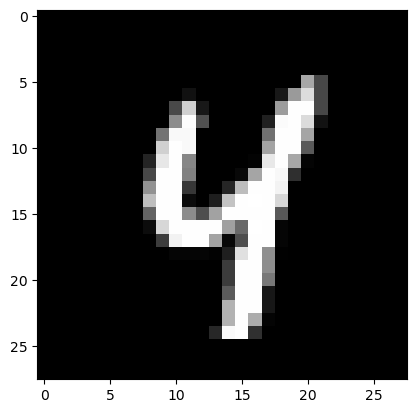

In [14]:
plt.imshow(X_train[1, :], cmap='gray', interpolation='None')

## Визуелизација на податоците

Со помош на алатките за визуелизација, наученi од предходно, ќе ги провериме следните карактеристики на множеството:

1. **Дали множеството е балансирано?:** одговорот на ова прашање ќе ни помогне да одлучиме каква метрика за евалуација треба да користиме.

2. **Дали секој од цифрите се слично позиционирани на сликите?:** Доколку цело множество на слики кои припаѓаат на една цифра е значително поместено во лево во споредба со другите цифри, тогаш моделот може предвидувањето на оваа цифра да ја прави според поместувањето, а не според тоа како е напишана цифрата. Иако ова би било точно за конкретното податочно множество, сепак во пракса не се подразбира дека сликите на таа иста цифра секогаш ќе бидат поместени во лево. Според тоа, мораме да провериме дали сите цифри се слично позиционирани во сликите. Дококлу некоја цифра значително отстапува, во лево, од другите тогаш ќе треба целото множество на слики кои припаѓаат на таа цифра да го поместиме во десно со цел да бидат централно поставени.

3. **Дали осветленоста на сликите помеѓу различни цифри е слична?:** Доколку цело множество на слики кои припаѓаат на една цифра е значително посветло од другите тогаш моделот може оваа цифра да ја предвидува според осветленоста, а не според тоа како е напишана цифрата.

### Визуелизирајте го бројот на слики од секоја класа (цифра)

**помош: seaborn.countplot()**

<Axes: ylabel='count'>

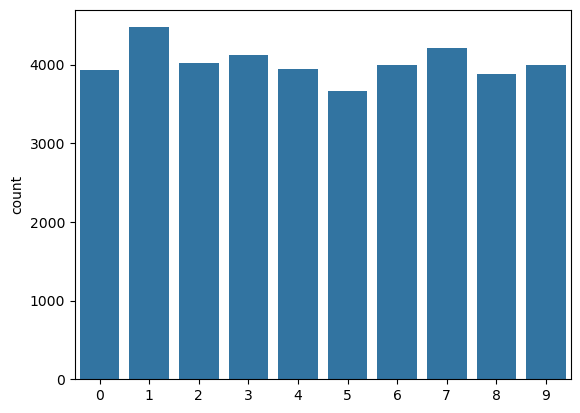

In [15]:
sns.countplot(x=y_train)

Може да се забележи дека множеството е релативно балансирано, па според тоа ќе можеме да користиме метрика за средна точност (Mean Accuracy)

### Прикажете по една слика од секоја класа (цифра) на график

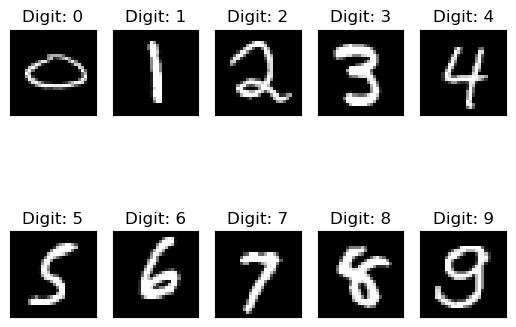

In [16]:
fig = plt.figure()
for i in range(10):
    r = randint(0, X_train[y_train == i].shape[0] - 1)
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[y_train == i][r], cmap='gray', interpolation='None')
    plt.title(f"Digit: {y_train[y_train == i][r]}")
    plt.xticks([])
    plt.yticks([])

### Прикажете по една слика од секоја класа (цифра) каде што сликата ќе биде средна вредност од сите слики на таа класа

**помош: X_train[y_train == ?].mean(axis=?) -> искористете го примерот од горната ќелија**

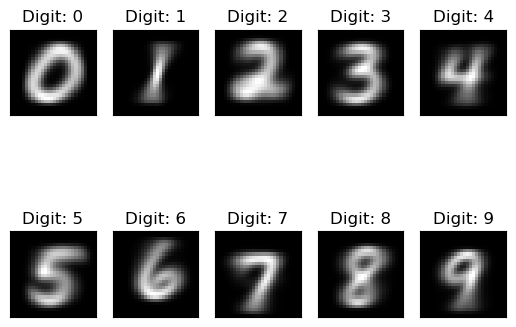

In [17]:
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_train[y_train == i].mean(axis=0), cmap='gray')
    plt.title(f"Digit: {i}")
    plt.xticks([])
    plt.yticks([])

Од средните слики за секоја цифра може да се види дека сите цифри се релативно централно поставени. Иако цифра 6 може да се помести малку подоле, а цифра 7 да се помести малку погоре, сепак ова ќе стане небитно кога ќе примениме проширување на податочното множество (data augmentation) во подолните ќелии.

### Исцртајте хистограм на средната слика, добиена од погоре, за секоја класа (цифра)

**помош: sns.histplot(X_train[y_train == i].mean(axis=0).ravel(), bins=50) -> искористете го примерот од горната ќелија**

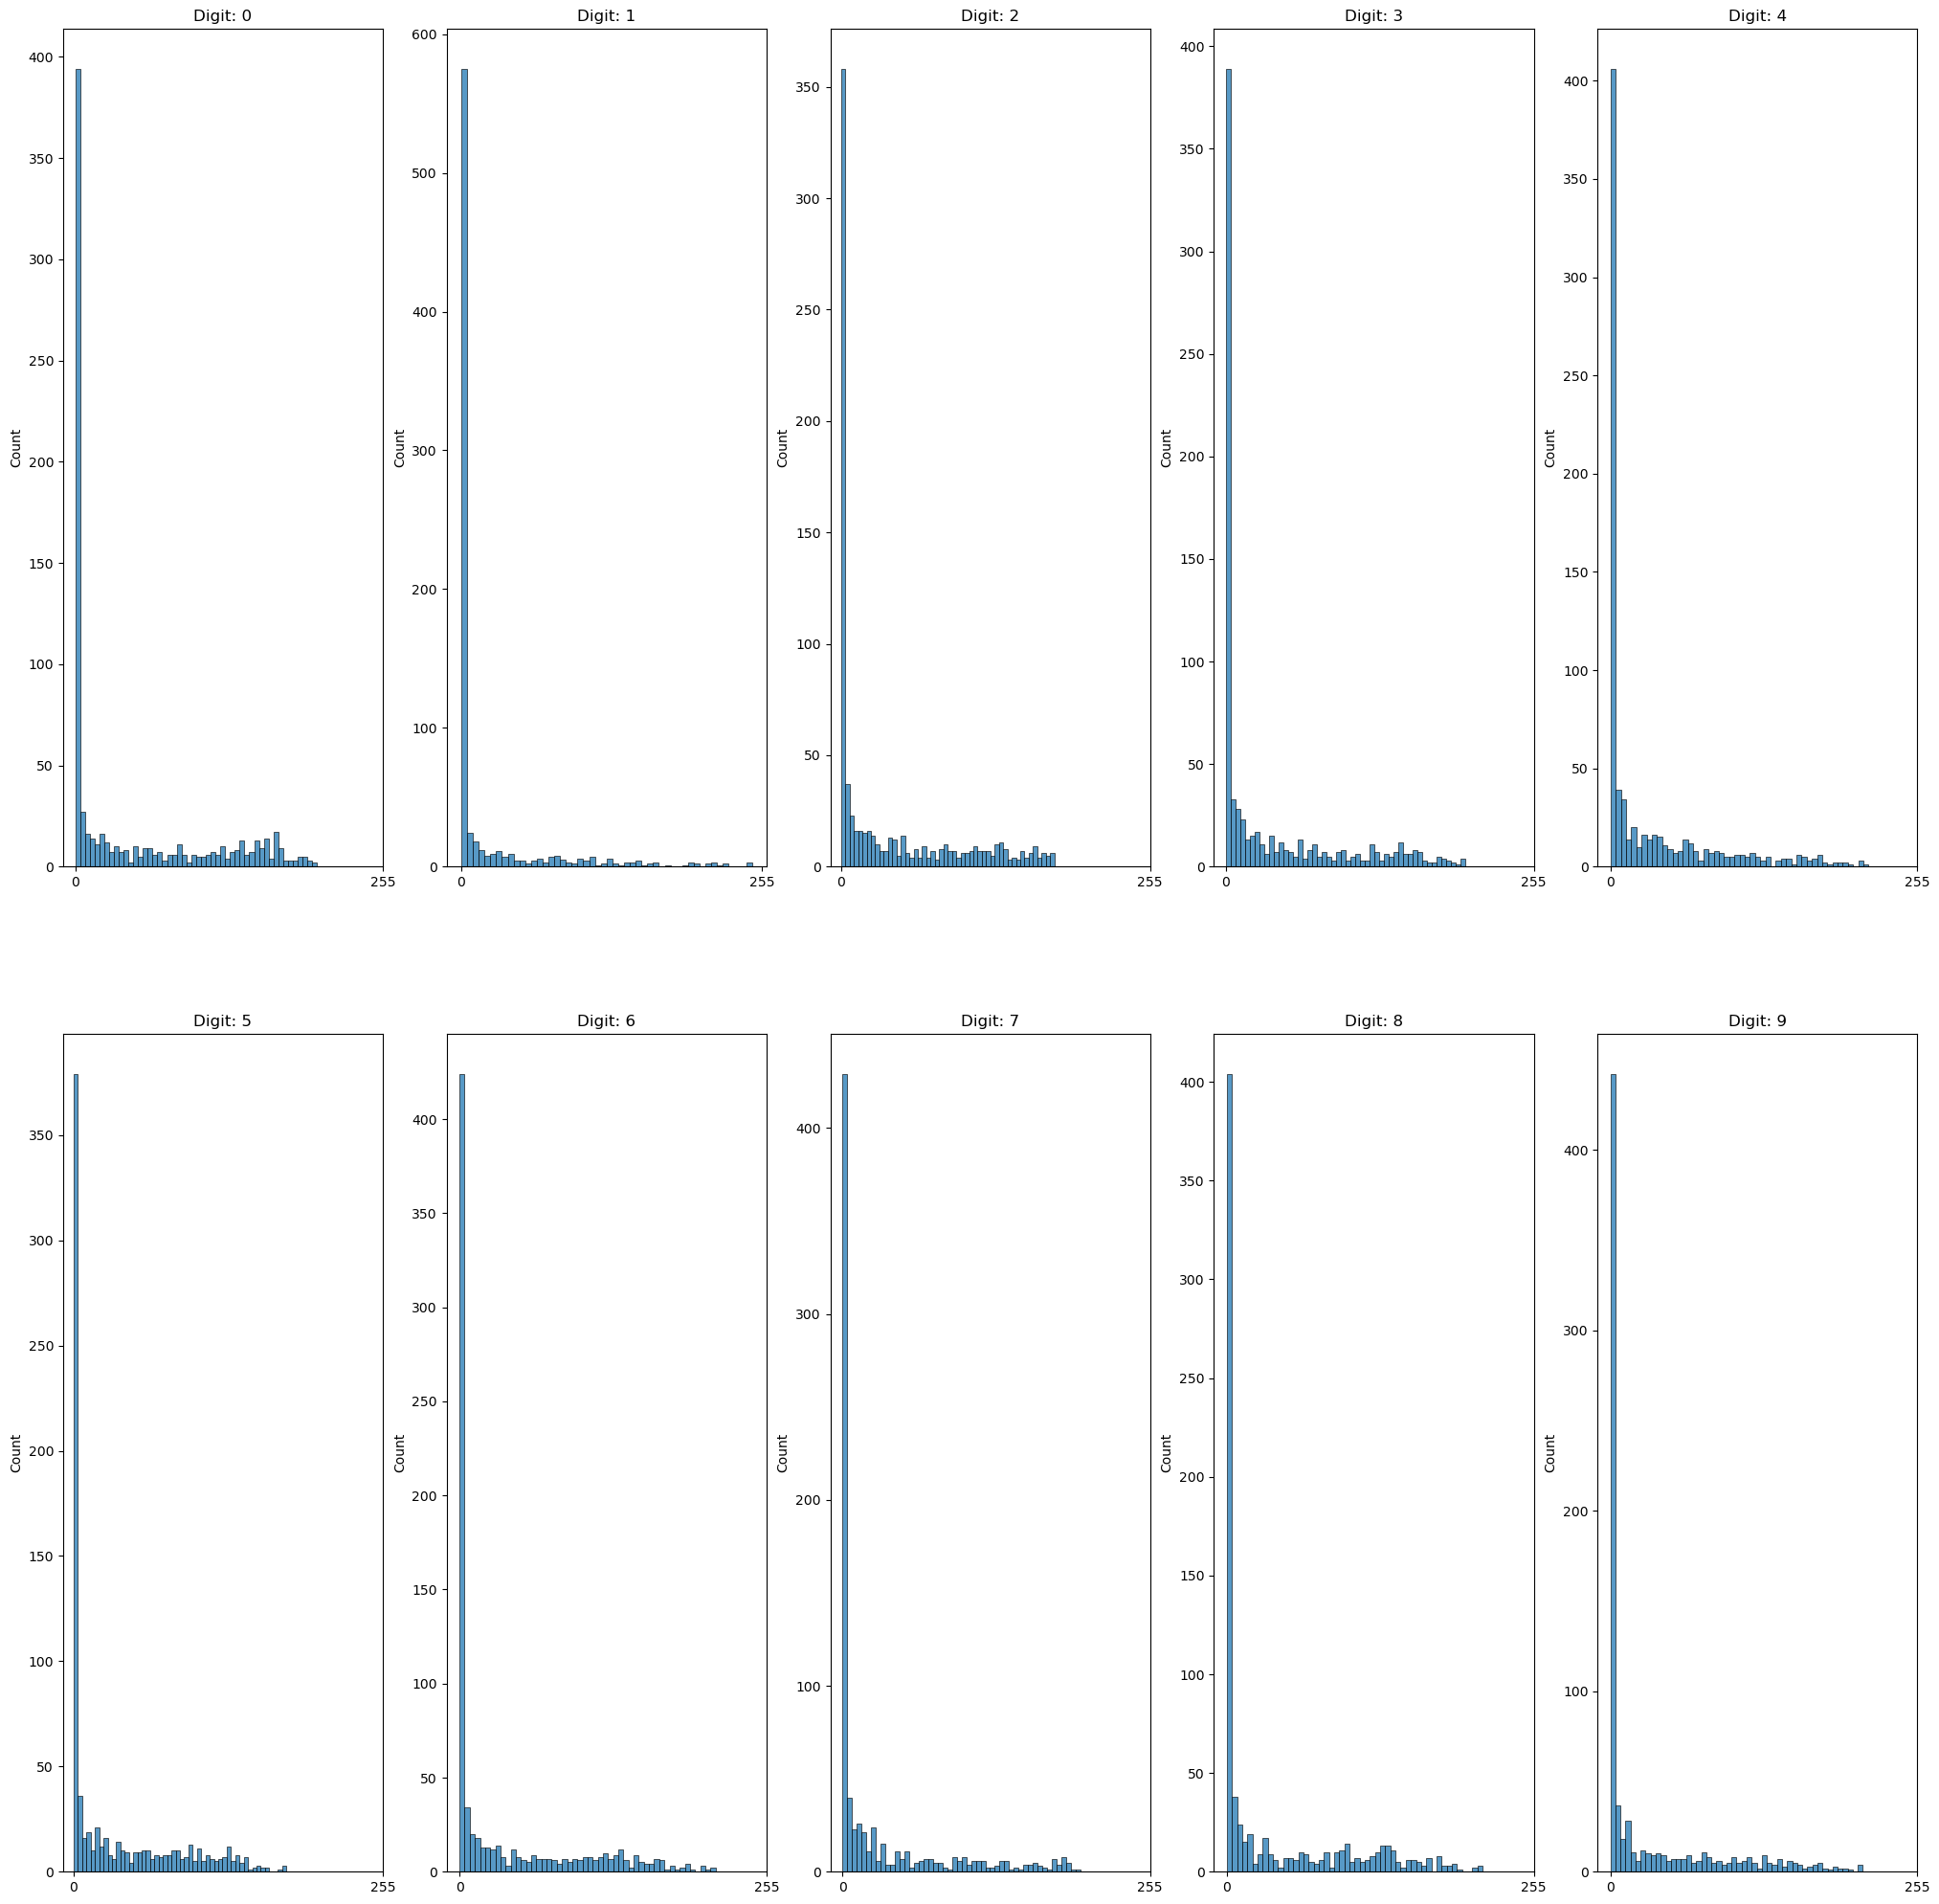

In [18]:
fig = plt.figure(figsize=(25, 25))
for i in range(10):
    plt.subplot(2, 5, i+1)
    sns.histplot(X_train[y_train == i].mean(axis=0).ravel(), bins=50)
    plt.title(f"Digit: {i}")
    plt.xticks([0, 255])

Очекувано е хистограмите за просечната слика на секоја цифра да бидат различни, но тоа што може да се забележи е дека ниту еден од нив значително не отстапува со многу повисоки или пониски вредности. Според тоа можеме да заклучиме дека сликите за секоја класа се релативно исто осветлени.

## Припрема и скалирање на множеството

На сликата подоле е претставена една општа архитектура на невронска мрежа. Може да се забележи дека истата е составена од три типа на слоеви.

1. **Влезен слој:** во нашиот случај влезниот слој ќе биде низа од 28*28 неврони наменети за секој пиксел од сликата
2. **Скриен слој:** скриениот слој може да биде низа од променлив број на неврони. Комплексноста на мрежата и времето потребно за тренирање зависи од комплексноста на скриенот слој. Доколку имаме низа од повеќе скриени слоеви тогаш овој тип на невронски мрежи уште се викаат длабоки невронски мрежи (deep neural nets)
3. **Излезен слој:** во нашиот случај излезниот слој ќе биде низа од 10 неврони, по еден за секоја класа (цифра)

<img src="nn_architecture.png" alt="drawing" style="width:500px;"/>

Познавајќи ја архитектурата на една невронска мрежа можеме да видиме дека влезот ќе биде еднодимензионална низа со големина 28*28, каде вредноста на секој пиксел претставува една карактеристика(feature). Поради тоа што сликите во нашето множество се складирани како 2-димензионални табели, ќе мора истите да ги трансформираме од облик (28, 28) во облик (28,)

Дополнително од истата архитектура може да се воочи дека излезот ќе биде еднодимензионална низа со големина 10. Според тоа y колоната од нашето множество ќе треба да ја трансформираме од облик (m, 1) со вредности во опсег [0, 9] во облик (m, 10) со вредности во опсег [0, 1], каде m е бројот на слики.

### Трансформирајте го обликот на секоја од X табелите каде што секоја слика ќе биде претставена како низа со големина 28*28

**помош: *.reshape()**

In [19]:
X_train = X_train.reshape(X_train.shape[0], 28*28)
X_val = X_val.reshape(X_val.shape[0], 28*28)
X_test = X_test.reshape(X_test.shape[0], 28*28)

проверете го реализираното така што ќе ги испечатите димензиите

In [20]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)


(40200, 784)
(19800, 784)
(10000, 784)


### Скалирање на податочното множество

Во предходните вежби применувавме стандардизација на податочното множество со цел да го забрзаме тренирањето, а воедно и да избегнеме големи вредности во пресметките на алгоритамот за тренирање.

Во овој случај стандардизацијата не е применлива од две причини:

1. **Секој пиксел би имал позитивни и негативни вредности од арбитрарна големина (во зависност од множеството):** Ова не е дозволиво бидејќи во областа на процесирање на сиви слики секој пиксел може да има вредност во опсег [0, 255] или [0.0, 1.0] каде минималната вредност е црна боја, а максималната вредност е бела боја.

2. **Промената на вредностa на секој пиксел комплетно би го измениле изгледот на сликата:** изгледот на сликата може да стане непрепознатлив така што формата на цифрата комплетно би се изгубила.

Според тоа, единствена метода што можеме да ја примениме во овој случај е скалирање. Истата ќе ја примениме со цел да го намалиме опсегот на вредности од [0, 255] во [0, 1.0]. Ова ќе ни помогне да избегнеме големи вредности во пресметките на алгоритамот за тренирање.

### Скалирајте ја секоја од X табелите така што секоја слика ќе и се промени опсегот од [0, 255] во [0.0, 1.0]

In [21]:
X_train = X_train / 255
X_val = X_val / 255
X_test = X_test / 255

Потврдете го реализираното така што ќе ја испечатите максималната и минималната вредност во X_train табелата.

In [22]:
X_train.min(), X_train.max()

(np.float64(0.0), np.float64(1.0))

### Трансформирајте ја секоја од y табелите така што истата ќе го добијат обликот со димензии (m, 10) со вредности во опсегот [0, 1]

**помош: np.utils.to_categorical()**

In [23]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [24]:
n_classes = 10
y_train = np_utils.to_categorical(y_train, n_classes)
y_val = np_utils.to_categorical(y_val, n_classes)
#y_test = np_utils.to_categorical(y_test, n_classes)

NameError: name 'np_utils' is not defined

In [ ]:
y_train.shape

In [25]:
X_train.shape

(40200, 784)

## Активациски функции кај невронски мрежи

Еден неврон на вештачка невронска мрежа може да се претстави како на сликата.

<img src="activation_function.avif" alt="drawing" style="width:500px;"/>

Невронот е составен од $n$ влезови, означени како $x_i$, каде секој влез се множи со тежински коефициент $w_i$. Излезот на невронот е означен со $a$.  Откако секој од влезовите ќе се помножат со соодветен тежински коефициент нивната сума се поставува на влез на активациска функција и истата го дава излезот. Оваа активациска функција може да има различен облик и истиот влијае на различни фактори како:

1. Опсег на вредноста на излез од невронот
2. Облик на вредноста/вредностите на излез од мрежата
3. Способност на мрежата брзо да се тренира
4. Способност на мрежата да ги користи сите неврони
5. Дали мрежата се користи за проблем на класификација или регресија

итн...

### Активациска функција Sigmoid (Logistic Function)

Сигмоид функцијата потекнува од логистичка регресија. Од тука може да се забележи еквиваленцијата дека невронска мрежа со еден неврон, кој користи сигмоид активациска функција, претставува всушност логистичка регресија.

Оваа функција може да се претстави со следната равенка:

$$f(x) = \frac{1}{1 + e^{-x}}$$

<center><img src="sigmoid.png" alt="drawing" style="width:500px;"/></center>


Изводот на оваа функција е:
$$f'(x) = f(x)(1-f(x))$$

<center><img src="dsigmoid.png" alt="drawing" style="width:500px;"/></center>

Од графикот може да се забележи дека изводот дава многу мала вредност во случаи кога $x<-3 \land x>3$. Познавајќи го принципот на работа на backpropagation алгоритмот, при тренирање на една невронска мрежа, очигледно е дека за опсези $x<-3 \land x>3$ функцијата ќе дава многу мали градиенти кои можат да се поистоветат со многу бавно тренирање. Ова уште се нарекува "Vanishing gradient problem".

**Предности**
* Монотона и диференцијабилна: што ја прави погодна за математички пресметки
* Ограничена во опсег [0, 1]: што ја прави погодна за проблеми на класификација чиј излез би се интерпретирал како веројатност
* Нелинеарна: што ја прави погодна за тренирање на комплексни модели на предвидување. Линеарните функции на предвидување не се погодни бидејќи истите на излез секогаш ќе даваат линеарни изрази, што значи дека нема да можат да предвидуваат нелинеарни зависности. Нелинеарните зависности се најчести во пракса.

**Недостатоци**
* Vanishing gradient problem: функцијата дава мали градите во определни опсези. Ова значи дека тренирањето на невронската мрежа станува се побавно, како што градиент се приближува кон 0.
* Излезот не е симетричен околу x-оска: излезот на функцијата е асиметричен бидејќи дава само позитивни вредности на излез. Ова предизвикува поместување на средната вредност на математичките пресметки, што некогаш може да предизвика отежнување и нестабилност при тренирање.

### Активациска функција tanh (тангенс хиперболикум)

Оваа функција е многу слична на сигмоид функцијата. Таа има слична s-форма како и сигмоид функцијата со исклучок на тоа што излезот е во опсег [-1, 1]. Според тоа таа ќе има слични карактеристики како сигмоид функцијата, со исклучок на тоа што истата е симетрична во однос на x-оската.

Оваа функција може да се претстави со следната равенка:

$$f(x) = tanh(x) = \frac{e^x-e^{-x}}{e^x+e^{-x}}$$

<center><img src="tanh.png" alt="drawing" style="width:500px;"/></center>

Изводот на оваа функција е:
$$f'(x) = sech(x)^2$$
<center><img src="dtanh.png" alt="drawing" style="width:500px;"/></center>

Како што може да се види од изводот на функцијата, истиот проблем на на мали градиенти постои и кај оваа активациска функција.

**Предности**
* Монотона и диференцијабилна: што ја прави погодна за математички пресметки
* Нелинеарна: што ја прави погодна за тренирање на комплексни модели на предвидување.
* Излезот е симетричен во однос на x-оска.

**Недостатоци**
* Vanishing gradient problem: функцијата дава мали градиенти во определни опсези. Ова значи дека тренирањето на невронската мрежа станува сe' побавно, како што градиентот се приближува кон 0.

### Активациска функција ReLU (Rectified Linear Unit)
Оваа активациска функција значително се разликува од предходните. Иако навидум оваа функција изгледа како да е линеарна, сепак ограничувањето на 0 за негативни вредности е тоа што ја прави нелинеарна. 

Оваа функција може да се претстави со следната равенка:

$$f(x) = max(0,x)$$

<center><img src="relu.png" alt="drawing" style="width:500px;"/></center>


Изводот на оваа функција е:
$$f(x) = \begin{cases}
1  & \text{if} x \ge 0\\
0 & \text{if} x < 0,\\
\end{cases}$$

<center><img src="drelu.png" alt="drawing" style="width:500px;"/></center>

Како што може да се забележи, изводот на оваа функција e константа за целиот опсег. Според тоа, проблемот на "vanishing gradient" е комплетно елиминиран. Сепак, тоа што загрижува е фактот дека градиентот е 0 за опсегот (-$\infty$, 0). Ова значи дека некои неврони при тренирање возможно е воопшто да не се тренираат поради тоа што нивниот влез е во опсег на негативни вредности. Ова може да доведе до "мртви неврони" кои никогаш нема да дадат вредност на излез која е различна од 0.

**Предности**
* Монотона и диференцијабилна по делови: што ја прави погодна за математички пресметки
* Нелинеарна: што ја прави погодна за тренирање на комплексни модели на предвидување.
* Компјутационо ефикасна: многу полесно е да се пресметуваат линеарни изрази отколку нелинеарни (експоненцијални и tanh функции)
* Елиминација на "vanishing gradient problem" за позитивни вредности
* Може да се користи во излезниот слој кога се тренира модел на регресија

**Недостатоци**
* Проблем на појава на мртви неврони при тренирање како резултат на "vanishing gradient problem" за негативни вредности
* Асиметрична околу x-оска

### Активациска функција Softmax
Составна компонента на софтмакс функцијата е сигмоид функцијата, која беше прикажана погоре. Имено, софтмакс го решава проблемот со кој се соочува сигмоид во случаеви кога се тренира модел на класификација каде бројот на класи е поголем од 2.

Пр. Замислете дека имаме проблем на класификација каде што треба да предвидиме дали на една слика се наоѓа куче, маче или папагал. Во тој случај излезниот слој на невронската мрежа би имал 3 неврони каде секој од нив би бил задолжен за секоја класа индивидуално.

Кога би користеле само сигмоид функција за овие три неврони, тогаш постојат случаеви каде на излез би добиле (0.8, 0.7, 0.6) за секоја класа индивидуално. Од тука се поставува прашањето на која класа би припаѓала сликата? 

Софтмакс функцијата го решава овој проблем така што секогаш ни гарантира дека сумата на излезите од трите неврона секогаш ќе биде еднаква на единица. Или во овој случај би можеле да добиеме излез од следниот облик (0.3, 0.3, 0.4). На тој начин одлуката за тоа на која класа припаѓа сликата значително ни се олеснува.

Математички оваа функција може да се претстави како:

$$softmax(x_i) = \frac{e^{x_i}}{\sum_{j=1}^{n}e^{x_j}} $$

каде i и j го означуваат конкретниот неврон на класата, а n го означува вкупниот број на класи.

Земајќи го примерот од погоре каде излезните неврони на излез даваат (0.8, 0.7, 0.6) тогаш со помош на софтмакс функцијата можеме излезот да го пресметаме на следниот начин:

* неврон 1: $softmax(0.8) = \frac{e^{0.8}}{e^{0.8} + e^{0.7} + e^{0.6}} = 0.3672$
* неврон 2: $softmax(0.7) = \frac{e^{0.7}}{e^{0.8} + e^{0.7} + e^{0.6}} = 0.3322$
* неврон 3: $softmax(0.6) = \frac{e^{0.6}}{e^{0.8} + e^{0.7} + e^{0.6}} = 0.3006$

Од тука може да се забележи дека сумата на излезите од трите неврони секогаш ќе изнесува 1 и според тоа се добива подобра интерпретација од аспект на теорија на веројатност.

### Повеќе информации за различни активациски функции може да се најдат [тука](https://arxiv.org/pdf/2109.14545)

## Градење на една невронска мрежа со помош на keras
Keras претставува библиотека за вештачки невронски мрежи. Оваа библиотека не имплементира алгоритми за оптимизација и модели, туку истата е базирана на постоечки библиотеки за невронски мрежи како: theano, tensorflow, JAX, PyTorch.

Според тоа Keras може да се опише како интерфејс за горе наведените библиотеки. Тоа што ја прави Keras практична во однос на горе наведените библиотеки е тоа што дозволува брз и лесен развој на невронски мрежи.

### Пример
За да ја изградиме невронската мрежа, претставена на сликата, ќе ги искористиме функциите Sequental(), Dense() и методата add().

<img src="nn_architecture.png" alt="drawing" style="width:500px;"/>

**Најпрво го дефинираме моделот**

In [26]:
model = Sequential()

**Потоа го додаваме секој нареден слој со соодветен број на неврони и соодветна активациска функција.**

Во овој случај имаме:
1. 1 влезен слој со 4 неврони
2. два скриени слоја по 5 неврони
3. 1 излезен слој со 4 неврони

Ќе искористиме ReLU активациска функција за сите неврони освен излезните. Излезните неврони ќе користат софтмакс.

In [27]:
model.add(Dense(units=5, activation='relu', input_shape=(4,)))
model.add(Dense(units=5, activation='relu'))
model.add(Dense(units=3, activation='softmax'))

/home/rademicov/.var/app/org.jupyter.JupyterLab/config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-11-11 15:38:26.708872: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


**Позначајни аргументи на Dense() функцијата:**
1. **units:** број на неврони во слојот
2. **activation:** активациска функција
3. **input_shape:** облик на слојот. Обликот најчесто е низа, но може да биде и матрица во случај конволуциски мрежи.

За тренирање на мрежата се користат model.compile() и model.fit() функциите.

**Позначајни аргументи на model.compile()**
1. **loss:** Се дефинира кој тип на функција на цена. Пример: "categorical_crossentropy", "mean_squared_error", "poisson". Изборот најмногу зависи од тоа дали проблемот е класификација или регресија.
2. **metrics:** Се дефинираат метрики за евалуација. Може да се користат повеќе метрики. Пример: "accuracy", "mean_squared_error", "top_k_categorical_accuracy".
3. **optimizer:** Алгоритам за оптимизација. Пример: "SGD", "adam", "rmsprop".

**Позначајни аргументи на model.fit()**
1. **batch_size:**: Тренирањето е од типот mini batch, па затоа се дефинира големина на шаржер од множеството за тренирање кој ќе се користи за една епоха на тренирање. Една епоха на тренирање подразбира мрежата да се истренира на онолку шаржери колку што може да се содржат во целото податочно множество.
2. **epochs:** Број на епохи за тренирање. Колку повеќе епохи толку подобри резултати ќе дава мрежата, но и побавно ќе се тренира.

## Општи факти кои би можеле да помогнат во пракса при тренирање на една невронска мрежа
### Проблем на многу мала невронска мрежа
Иако мрежата е лесна за тренирање сепак не е доволно голема за да најде значајни карактеристики кои би го олесниле предвидувањето. Ваквите мрежи најчесто се карактеризираат со помала точност, но сепак се полесни за тренирање. Нема арбитрарна големина која ќе каже што значи една мрежа да е мала, но сепак може да го земете условот: бројот на скриени неврони да биде значајнo помал од бројот на влезни влезови.

### Проблем на многу голема невронска мрежа
Логично би било резонирањето дека колку невронската мрежа e поголема  тогаш таа ќе наоѓа повеќе позначајни карактеристики и ќе ги искористува за добро предвидување. Сепак мора да се земе предвид дека овие мрежи се тешки за тренирање, а најчесто и тежнеат да бидат претренирани(overfitting). 

За таа намена keras нуди **Dropout** функција којашто при тренирање во секоја итерација ќе игнорира определено количество на неврони со цел да не се фокусира на тренирање само на мало подмножество на неврони кои ќе ја доведат мрежата во состојба на претренираност. Примената на Dropout функцијата може да ја интерпретирате како уште еден начин на регуларизација. Доколку сакате да применувате стандардна регуларизација за секој слој индивидуално тогаш можете да ја користите следната функција **ActivityRegularization**. Нема арбитрарна големина која ќе каже што значи една мрежа да е голема, но сепак може да го земете условот: бројот на скриени неврони да биде значајно поголем од бројот на влезни влезови.

### Идеална невронска мрежа
Не постои нешто такво како идеална невронска мрежа. Дури и да сте ја нашле најдобрата мрежа од вашето множество на предходно тренирани модели, никој не гарантира дека таа е идеалната. Не постојат правила за како да добиете идеална невронска мрежа, се' се сведува на проба и грешка преку менување на нејзината архитектура и нејзините хиперпараметри за тренирање. Доколку го познавате на значењето на хиперпараметрите тогаш полесно ќе стигнете до разумно решение на проблемот во спротивно може да изгубите повеќе време.

## Тренирање и евалуација на невронска мрежа 

### Креирајте невронска мрежа која на влез ќе ги добива сликите, а на излез ќе кажува за која цифра се работи. 

**Искористете ги следните параметри:**
* **Број на влезни неврони:** ?
* **Број на скриени слоеви:** 1 слој со 512 неврони
* **Број на излезни неврони:** ?
* **Функција на цена:** 'categorical_crossentropy'
* **Метрика за евалуација:** 'accuracy'
* **Алгоритам за оптимизација:** keras.optimizers.SGD(learning_rate=0.05, momentum=0.4, nesterov=True)

**Забелешка:** Алгоритмите како adam и rmsprop често водат до подобри резултати. Сега ќе користиме Stochastic Gradient Descent (SGD) бидејќи тој ни е познат. Приметете дека покрај learning_rate параметарот имаме и momentum. Со овој параметар всушност внесуваме нестерова инерција во оптимизацијата што може да ни помогне оптимизаторот да не заглавува во локални минимуми.


In [28]:
model = Sequential()
model.add(Dense(512, activation='relu', input_shape=(28*28, )))
model.add(Dense(10, activation='softmax'))
model.compile(loss='categorical_crossentropy', 
              metrics=['accuracy'], 
              optimizer=keras.optimizers.SGD(learning_rate=0.05, momentum=0.4, nesterov=True))

Повеќе информации за менување на стапката на учење(learning_rate) според Нестеров на следниот [линк](https://cedar.buffalo.edu/~srihari/CSE676/8.3%20BasicOptimizn.pdf).
Идејата е да се искористи поимот на инерција од реалниот свет и да се додаде при учењето на алгоритмот така што промената на тежините на мрежата ќе имаат инерција и нема слепо да се менуваат според градиентот. Ова ќе намали веројатноста тренирањето да падне во локален минимум, а исто така може и да го забрза процесот на учење.

### Истренирајте ја невронската мрежа на множеството за тренирање со помош на следните параметри

* **batch_size:** 128
* **epochs:** 30
* **validation_data:** искористете го множеството за тренирање

**Забелешка:** Поголема вредност за batch_size може да ја забрза конвергенцијата и да даде подобри резултати. Преголема вредност може да предизвика претренирање(overfitting). Зголемете го бројот на епохи доколку анализата на тренирањето ви потврди дека тренирањето не конвергирало.

In [29]:
history = model.fit(X_train, y_train, batch_size=128, epochs=30, verbose=1, validation_data=(X_val, y_val))

Epoch 1/30


ValueError: Arguments `target` and `output` must have the same rank (ndim). Received: target.shape=(None,), output.shape=(None, 10)

## Анализа на тренирањето
Визуелизација на процесот на тренирање може да ви каже дали моделот при тренирање конвергирал или не. Доколку тој не конвергирал тогаш треба да го зголемите бројот на епохи за да продолжите со тренирање. Ова го гледате според тоа дали наклонот на кривата на точноста води кон нејзино зголемување. 

Земете во предвид дека некогаш моделот може да има висока точност, но исто така и висока функција на цена. Ова се случува поради самата природа на Log функцијата која може да даде многу високи вредности за мал дел на точки од множеството кои значително ќе го зголемат просекот на функцијата на цена. Во вакви случаи точноста е померодавна од функцијата на цена бидејќи вас не ве интересира дали моделот предвидува лошо за мал број на слики туку дали ги предвидува точно поголемиот број на слики од множеството. Сепак ова зависи од проблемот кој се обидувате да го решите.

### На долните два графика се прикажани криви на учење (learning curves) за средната точност и функцијата на цена.

In [ ]:
fig = plt.figure(figsize=(20, 20))
plt.subplot(2, 1, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Accuracy function')
plt.xlabel('accuracy')
plt.ylabel('epochs')
plt.legend(['train', 'test'])

plt.subplot(2, 1, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Loss function')
plt.xlabel('loss')
plt.ylabel('epochs')
plt.legend(['train', 'test'])

## Евалуација
Кога ќе одлучите дека сте задоволни од вашиот истрениран модел, добро е да ги проверите неговите способности на множество кое не го видел предходно. За тоа ќе го примениме предходно дефинираното множество за тестирање. Не е препорачливо да го проверувате моделот многу често на ова множество. Колку повеќе го проверувате толку поголема е шансата за overfitting. Ако морате, тогаш поделбата на множеството(train_test_split)  правете ја со различно семе(seed) секој пат.

### Проверета ја средната точност (accuracy) и функцијата на цена за тест множеството

**помош: *.evaluate()**

In [30]:
print("Функција на на цена и процент на точно класифицирани слики: ", model.evaluate(X_test, to_categorical(y_test)))

NameError: name 'np_utils' is not defined

### Испечатете на екран колкав број на слики се предвидуваат точно, а колку се згрешени при предвидување на множеството за тестирање

In [31]:
predicted = model.predict_classes(X_test)
print("Број на точно и погрешно класифицирани слики: ", y_test[predicted == y_test].shape, y_test[predicted != y_test].shape)

AttributeError: 'Sequential' object has no attribute 'predict_classes'

### Прикажување на точно класифицирани слики

### По случаен избор прикажете 9 слики кои точно биле предвидени од моделот врз множеството за тестирање

In [32]:
fig = plt.figure(figsize=(10, 10))
for i in range(9):
    r = randint(0, X_test[predicted == y_test].shape[0] - 1)
    plt.subplot(6,3,i+1)
    plt.imshow(X_test[predicted == y_test][r].reshape(28,28), cmap='gray', interpolation='none')
    plt.title(f"Predicted: {predicted[predicted == y_test][r]}; Truth: {y_test[predicted == y_test][r]}")
    plt.xticks([])
    plt.yticks([])

NameError: name 'predicted' is not defined

<Figure size 1000x1000 with 0 Axes>

### Прикажување на погрешно класифицирани слики

### По случаен избор прикажете 9 слики кои погрешно биле предвидени од моделот врз множеството за тестирање

In [33]:
fig = plt.figure(figsize=(10, 10))
# plot 9 incorrect predictions
for i in range(9, 18):
    r = randint(0, X_test[predicted != y_test].shape[0] - 1)
    plt.subplot(6,3,i+1)
    plt.imshow(X_test[predicted != y_test][r].reshape(28,28), cmap='gray', interpolation='none')
    plt.title(f"Predicted: {predicted[predicted != y_test][r]}; Truth: {y_test[predicted != y_test][r]}")
    plt.xticks([])
    plt.yticks([])

NameError: name 'predicted' is not defined

<Figure size 1000x1000 with 0 Axes>

# Проширување на податочното множество (Data augmentation)
Доколку не сме задоволни од резултатите на моделот тогаш постојат повеќе фактори кои можат да бидат причина за тоа:
1. Лош избор на модел
2. Лошо истрениран модел
3. Потреба од карактеристики кои ќе носат повеќе информација за моделот
4. Мало множество за тренирање

Секоја од горе наведените причини може да се третира посебно, а во овој дел ние ќе се фокусираме само на последната. Многу често точноста на моделот може да биде подобрена со помош на поголемо податочно множество. Поголемо податочно множество подразбира да имаме поголем увид во различни слики кои што ќе го зголемат видикот на моделот и при тоа ќе овозможат да генерализира подобро.
Зголемувањето на податочното множество во многу реални случаи е невозможно или побарува огромно количество на рачна работа. Тука ќе покажеме техника за зголемување која што е многу лесна, а при тоа може и да ја подобри точноста на моделот.

Од визуелизацијата на податоците увидовме дека цифрите на сликите имаа простор да бидат прикажни малку полево или подесно во однос на другите. Исто така може да се случи и некоја цифра да бида малку повеќе ротирана од друга.

**На сликите подоле се прикажани две слики од множеството за тестирање на кои е прикажан бројот 9. Воочете ја разликата помеѓу начинот на кој се напишани двете цифри. Едната цифра има ротација во однос на другата. Според тоа, доколку во множеството има многу малку ротирани 9-ки под тој агол тогаш мрежата нема да може добро да предвидува на такви ротирани цифри. За таа намена ќе го зголемиме податочното множество така што тековните слики дополнително ќе ги ротираме и транслираме. За оваа намена ќе ја искористиме библиотеката за процесирање на слика OpenCV и истото ќе го реализирамо со помош на афини трансформации. За повеќе детали околу афини трансформации, ви препорачуваме да го погледнете следното [видео](https://www.youtube.com/watch?time_continue=95&v=AheaTd_l5Is&embeds_referring_euri=https%3A%2F%2Fwww.google.com%2F&source_ve_path=MjM4NTE).**

([], [])

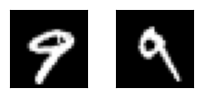

In [34]:
# постоење на ротација во цифрите
plt.figure(figsize=(2.5, 1))
plt.subplot(1, 2, 1)
plt.imshow(X_test[9].reshape(28,28), cmap='gray', interpolation=None)
plt.xticks([])
plt.yticks([])
plt.subplot(1, 2, 2)
plt.imshow(X_test[7].reshape(28,28), cmap='gray', interpolation=None)
plt.xticks([])
plt.yticks([])

Може да се забележи дека 7-та и 9-тата слика од множеството за тестирање ја прикажуваат истата цифра, но едната од нив е значително ротирана во однос на другата.

### Пример за транслација на една слика за 7 пиксели по x оска

([], [])

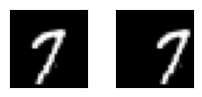

In [35]:
tmat = np.array([[1, 0, 7], 
               [0, 1, 0]], dtype=np.float32) 
plt.figure(figsize=(2.5, 1))
plt.subplot(1, 2, 1)
plt.imshow(X_train[0].reshape(28,28), cmap='gray', interpolation=None)
plt.xticks([])
plt.yticks([])
plt.subplot(1, 2, 2)
plt.imshow(cv2.warpAffine(X_train[0].reshape(28,28), tmat, (28, 28)), cmap='gray', interpolation=None)
plt.xticks([])
plt.yticks([])

### Дополнете го податочното множество за тренирање така што ќе ја транслирате секоја од сликите по x-оска за онолку пиксели прикажани во dx_list

dx_list = [1, 3, 5, 7, -1, -3, -5, -7]

**помош: користете го примерот од горната ќелија**

In [36]:
dx_list = [1, 3, 5, 7, -1, -3, -5, -7]
X_train_trans = []
y_train_trans = []

for dx in dx_list:
    for image, cclass in zip(X_train, y_train):
        image = image.reshape(28, 28)
        tmat = np.float32([[1, 0, dx], 
                           [0, 1, 0]]) 
        X_train_trans.append(cv2.warpAffine(image, tmat, (28, 28)).reshape(28*28))
        y_train_trans.append(cclass)
        
X_train_trans = np.array(X_train_trans)
y_train_trans = np.array(y_train_trans)

### Пример за ротација на една слика околу центар со координати (14, 14) за 50 степени и без скалирање (1)

([], [])

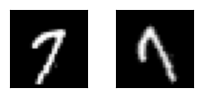

In [37]:
rotmat = cv2.getRotationMatrix2D((14, 14), 50, 1)
plt.figure(figsize=(2.5, 1))
plt.subplot(1, 2, 1)
plt.imshow(X_train[0].reshape(28,28), cmap='gray', interpolation=None)
plt.xticks([])
plt.yticks([])
plt.subplot(1, 2, 2)
plt.imshow(cv2.warpAffine(X_train[0].reshape(28,28), rotmat, (28, 28)), cmap='gray', interpolation=None)
plt.xticks([])
plt.yticks([])

### Дополнете го податочното множество за тренирање така што ќе ја ротирате секоја од сликите околу нивниот центар за онолку степени прикажани во dtheta_list

dtheta_list = [10, 20, 40, 60, -10, -20, -40, -60]

**помош: користете го примерот од горната ќелија**

In [38]:
dtheta_list = [10, 20, 40, 60, -10, -20, -40, -60]
X_train_rots = []
y_train_rots = []

for dtheta in dtheta_list:
    for image, cclass in zip(X_train, y_train):
        image = image.reshape(28, 28)
        rotmat = cv2.getRotationMatrix2D((14, 14), dtheta, 1)
        X_train_rots.append(cv2.warpAffine(image, rotmat, (28, 28)).reshape(28*28))
        y_train_rots.append(cclass)
        
X_train_rots = np.array(X_train_trans)
y_train_rots = np.array(y_train_rots)

In [39]:
(X_train_trans.shape, X_train_rots.shape, y_train_trans.shape, y_train_rots.shape)

((321600, 784), (321600, 784), (321600,), (321600,))

In [40]:
X_train = np.vstack((X_train, X_train_trans, X_train_rots))
y_train = np.vstack((y_train, y_train_trans, y_train_rots))

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 1, the array at index 0 has size 40200 and the array at index 1 has size 321600

# Тренирање и евалуација со проширено податочно множество

### Истренирајте го моделот од поново со новото множество за тренирање и споредете ги резултатите од предходно

In [ ]:
model = Sequential()
model.add(Dense(512, activation='relu', input_shape=(28*28, )))
model.add(Dense(10, activation='softmax'))

In [ ]:
model.compile(loss='categorical_crossentropy', 
              metrics=['accuracy'], 
              optimizer=keras.optimizers.SGD(learning_rate=0.05, momentum=0.4, nesterov=True)) # алгоритмите како rmsprop и adam често водат до подобри резултати во тренирањето

In [ ]:
history = model.fit(X_train, y_train, batch_size=128, epochs=30, verbose=1, validation_data=(X_val, y_val))

### Исцртајте ги кривите на учење

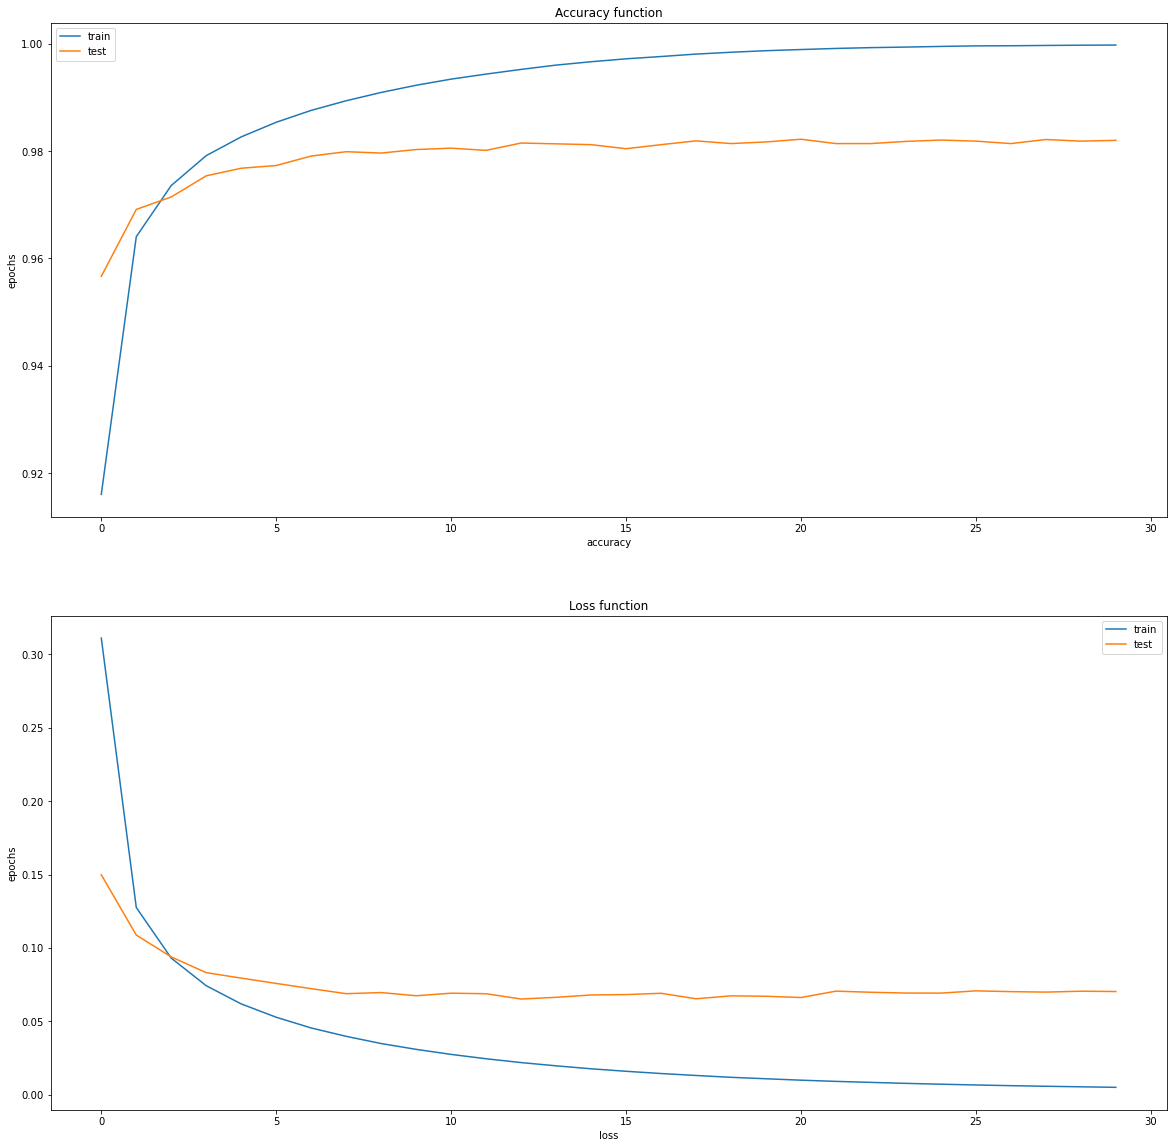

In [37]:
fig = plt.figure(figsize=(20, 20))
plt.subplot(2, 1, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Accuracy function')
plt.xlabel('accuracy')
plt.ylabel('epochs')
plt.legend(['train', 'test'])

plt.subplot(2, 1, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Loss function')
plt.xlabel('loss')
plt.ylabel('epochs')
plt.legend(['train', 'test'])

### Проверета ја средната точност (accuracy) и функцијата на цена за тест множеството

**помош: *.evaluate()**

In [38]:
print("Функција на цена и процент на точно класифицирани слики: ", model.evaluate(X_test, np_utils.to_categorical(y_test), verbose=2))

Функција на цена и процент на точно класифицирани слики:  [0.056938405045425314, 0.9843999743461609]


### Испечатете на екран колкав број на слики се предвидуваат точно, а колку се згрешени при предвидување на множеството за тестирање

In [39]:
predicted = model.predict_classes(X_test)
print("Број на точно и погрешно класифицирани слики: ", y_test[predicted == y_test].shape, y_test[predicted != y_test].shape)

Број на точно и погрешно класифицирани слики:  (9844,) (156,)


Можеме да забележиме дека успеавме средната точност да ја зголемиме од 0.9756 на 0.9761. Односно успеавме 6 слики повеќе да предвидиме точно во споредба со предходниот модел.

Совети за подобрување на моделот:
1. Пронајдете ги оние цифри кои моделот погрешно ги класифицира, а сепак се очигледни за човекот.
2. Генерирајте подмножество на овие цифри
3. Зголемете го ова подмножество така што ќе ги ротирате, транслирате и скалирате(зголемени и намалени).
4. Додадете го ова подмножество на множеството за тренирање и проверете ги резултатите

**Доколку целите кон модел кој ќе предвидува совршено тогаш го препорачуваме следниот научен [труд](https://arxiv.org/abs/1202.2745)**

# Зачувување и вчитување на моделот
Откако ќе добиете задоволителни резултати од моделот препорачливо е да го зачувате со цел да го имате за споредба со други идни модели. На крајот можете да го одберете најдобриот од сите зачувани. Исто така можете да примените и логистичка регресија каде на влез како карактеристики ќе бидат излезните резултати од сите модели за секоја точка. На овој начин ќе се добие тежинска низа од предвидувањата на сите модели која што може да биде подобра од само еден.

### Зачувајте го моделто под име "NN_1" и потоа прочитајте го одново

**помош: *.save(), keras.models.load_model()**

In [40]:
model.save('NN_1')

In [41]:
model = keras.models.load_model('NN_1')

Детални информации околу теоријата на невронски мрежи можете да најдете во следнава [бесплатна онлајн книга](http://neuralnetworksanddeeplearning.com/index.html).